In [8]:
import pandas as pd

df = pd.read_csv('ats_cluster_v1.csv')

df.head()

,tenure,MonthlyCharges,Dependents,SeniorCitizen,Churn
0,0.013889,0.069307,0,0,1
1,0.569444,0.069307,0,0,0
2,0.722222,0.009901,1,0,0
3,0.013889,0.574257,0,0,1
4,0.930556,0.326733,0,0,0


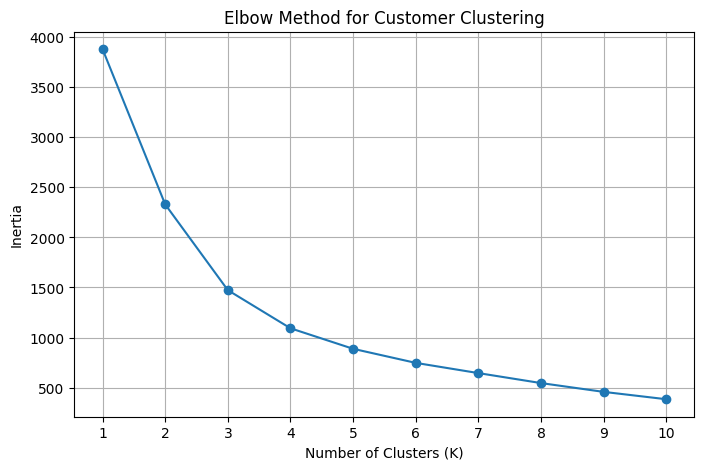

In [9]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Select the four variables for clustering
X = df[['tenure', 'MonthlyCharges', 'Dependents', 'SeniorCitizen']]

# Test different numbers of clusters
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

# Create the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Customer Clustering')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [10]:
from sklearn.cluster import KMeans

# Train K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Assign each customer to a cluster
df['Cluster'] = kmeans.fit_predict(X)

# Count customers in each cluster
print("Number of customers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

Number of customers in each cluster:
Cluster
0    2023
1    1138
2    3882
Name: count, dtype: int64


In [11]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

# Compare 3 and 4 clusters
for k in [3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=2000,
        random_state=42
    )

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 3, Silhouette Score = 0.5175
K = 4, Silhouette Score = 0.4692


In [12]:
# Analyse customer characteristics in each cluster
cluster_summary = df.groupby('Cluster').agg(
    Customers=('Cluster', 'size'),
    Average_Tenure=('tenure', 'mean'),
    Average_MonthlyCharges=('MonthlyCharges', 'mean'),
    Dependents_Rate=('Dependents', 'mean'),
    SeniorCitizen_Rate=('SeniorCitizen', 'mean'),
    Churn_Rate=('Churn', 'mean')
)

# Convert proportions to percentages
cluster_summary['Dependents_Rate'] *= 100
cluster_summary['SeniorCitizen_Rate'] *= 100
cluster_summary['Churn_Rate'] *= 100

# Display the results
print(cluster_summary.round(2).to_string())

         Customers  Average_Tenure  Average_MonthlyCharges  Dependents_Rate  SeniorCitizen_Rate  Churn_Rate
Cluster                                                                                                    
0             2023            0.53                    0.40           100.00                 0.2       15.03
1             1138            0.46                    0.61             7.64               100.0       41.83
2             3882            0.40                    0.45             0.00                 0.0       28.05


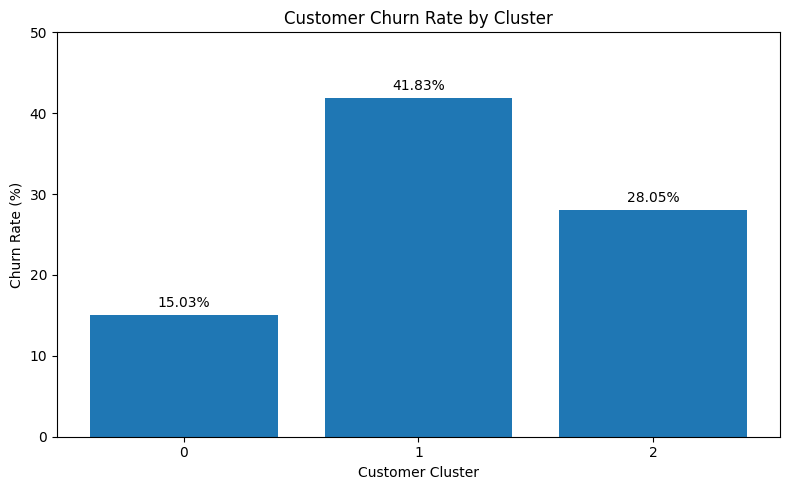

In [13]:
import matplotlib.pyplot as plt

# Create a bar chart of churn rates
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_summary.index.astype(str),
    cluster_summary['Churn_Rate']
)

plt.xlabel('Customer Cluster')
plt.ylabel('Churn Rate (%)')
plt.title('Customer Churn Rate by Cluster')

plt.ylim(0, 50)

# Add percentage labels above each bar
for i, value in enumerate(cluster_summary['Churn_Rate']):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

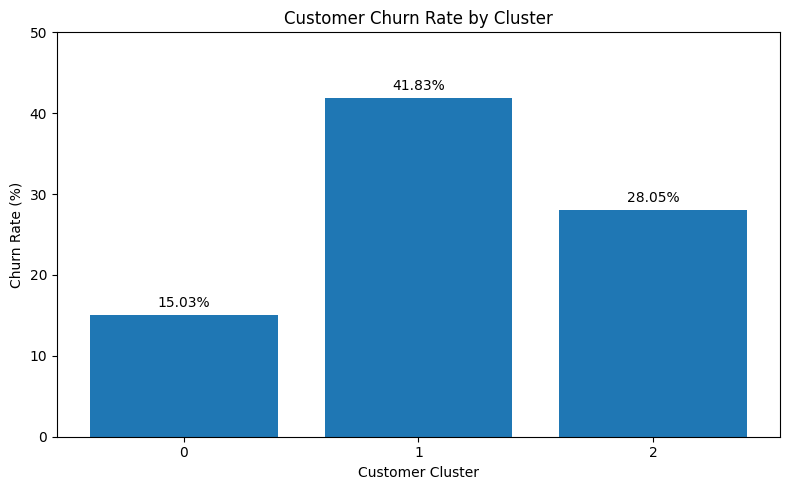

In [14]:
plt.figure(figsize=(8, 5))
plt.bar(
    cluster_summary.index.astype(str),
    cluster_summary['Churn_Rate']
)
plt.xlabel('Customer Cluster')
plt.ylabel('Churn Rate (%)')
plt.title('Customer Churn Rate by Cluster')

for i, value in enumerate(cluster_summary['Churn_Rate']):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.ylim(0, 50)
plt.tight_layout()
plt.savefig('customer_churn_by_cluster.png', dpi=300)
plt.show()

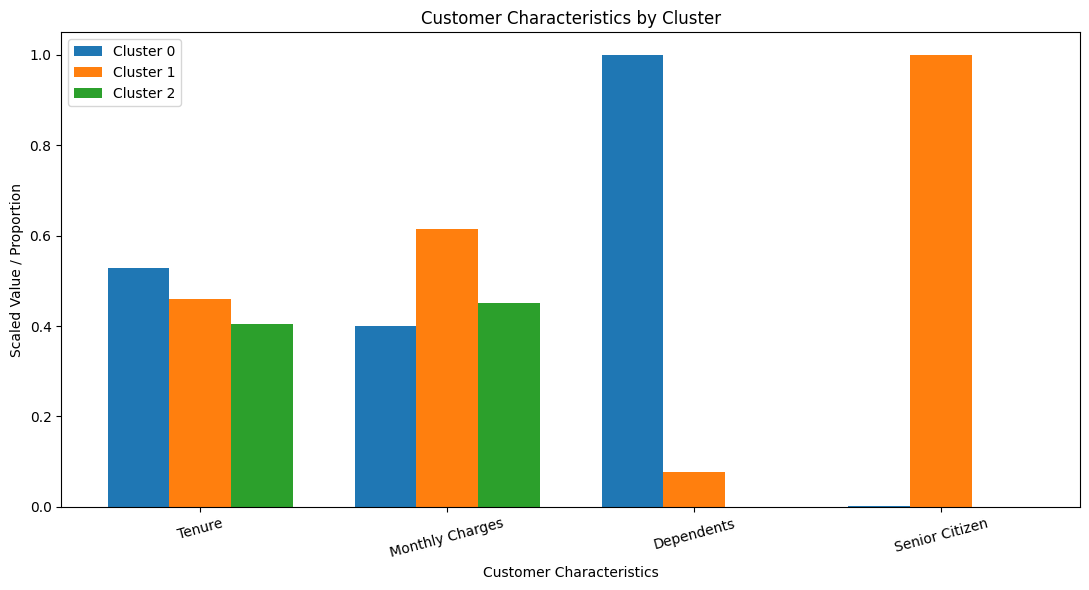

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Select the average values for each cluster
features = [
    'Average_Tenure',
    'Average_MonthlyCharges',
    'Dependents_Rate',
    'SeniorCitizen_Rate'
]

# Convert percentages to proportions for comparison
comparison = cluster_summary[features].copy()
comparison['Dependents_Rate'] /= 100
comparison['SeniorCitizen_Rate'] /= 100

# Create a grouped bar chart
x = np.arange(len(features))
width = 0.25

plt.figure(figsize=(11, 6))

for i, cluster in enumerate(comparison.index):
    plt.bar(
        x + (i - 1) * width,
        comparison.loc[cluster],
        width,
        label=f'Cluster {cluster}'
    )

plt.xlabel('Customer Characteristics')
plt.ylabel('Scaled Value / Proportion')
plt.title('Customer Characteristics by Cluster')

plt.xticks(
    x,
    ['Tenure', 'Monthly Charges', 'Dependents', 'Senior Citizen'],
    rotation=15
)

plt.legend()
plt.tight_layout()

# Save the graph
plt.savefig('customer_characteristics_by_cluster.png', dpi=300)

plt.show()

In [16]:
# Detailed cluster analysis for Jira CCDAT5-21

cluster_details = df.groupby('Cluster').agg(
    Total_Customers=('Cluster', 'size'),
    Average_Tenure=('tenure', 'mean'),
    Average_MonthlyCharges=('MonthlyCharges', 'mean'),
    Dependents_Percentage=('Dependents', 'mean'),
    SeniorCitizen_Percentage=('SeniorCitizen', 'mean'),
    Churn_Percentage=('Churn', 'mean')
)

# Convert proportions to percentages
percentage_columns = [
    'Dependents_Percentage',
    'SeniorCitizen_Percentage',
    'Churn_Percentage'
]

cluster_details[percentage_columns] *= 100

# Add customer percentage
cluster_details['Customer_Percentage'] = (
    cluster_details['Total_Customers'] / len(df) * 100
)

print("K-Means Clustering Model Results")
print("Number of clusters: 3")
print("Total customers:", len(df))
print()
print(cluster_details.round(2).to_string())

K-Means Clustering Model Results
Number of clusters: 3
Total customers: 7043

         Total_Customers  Average_Tenure  Average_MonthlyCharges  Dependents_Percentage  SeniorCitizen_Percentage  Churn_Percentage  Customer_Percentage
Cluster                                                                                                                                                 
0                   2023            0.53                    0.40                 100.00                       0.2             15.03                28.72
1                   1138            0.46                    0.61                   7.64                     100.0             41.83                16.16
2                   3882            0.40                    0.45                   0.00                       0.0             28.05                55.12


In [17]:
cluster_details.to_csv('cluster_analysis_summary.csv')

In [18]:
import joblib
joblib.dump(kmeans, 'kmeans_model.pkl')

['kmeans_model.pkl']